In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

df = pd.read_csv("uber.csv")

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647 

In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Shape: (200000, 9)

Columns:
Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB
None

Statistical Summary:
         Unnamed: 0    fare_am

In [5]:

# Remove unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True)

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], utc=True, errors='coerce'
)

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Remove invalid fare amounts
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 200)]

# Remove invalid passenger counts
df = df[(df['passenger_count'] >= 1) &
        (df['passenger_count'] <= 6)]

# Remove geographically invalid coordinates
df = df[
    df['pickup_longitude'].between(-75, -72.5) &
    df['dropoff_longitude'].between(-75, -72.5) &
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42)
]

print("Preprocessing completed!")
print("Shape after cleaning:", df.shape)
print(df.head())


Preprocessing completed!
Shape after cleaning: (195096, 7)
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  


In [6]:

# Function to calculate distance using Haversine formula
def calculate_distance(lat1, lon1, lat2, lon2):

    R = 6371  # Earth's radius in km

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2)**2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2)**2)

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# Calculate ride distance
df['distance'] = calculate_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# Extract date and time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# Remove unrealistic distances
df = df[(df['distance'] > 0) & (df['distance'] <= 100)]

# Drop original datetime column
df.drop('pickup_datetime', axis=1, inplace=True)

print(df.head())


   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  distance  hour  day  month  year  \
0         40.723217                1  1.683323    19    7      5  2015   
1         40.750325                1  2.457590    20   17      7  2009   
2         40.772647                1  5.036377    21   24      8  2009   
3         40.803349                3  1.661683     8   26      6  2009   
4         40.761247                5  4.475450    17   28      8  2014   

   day_of_week  
0            3  
1            4  
2            0  
3            4  
4            3  


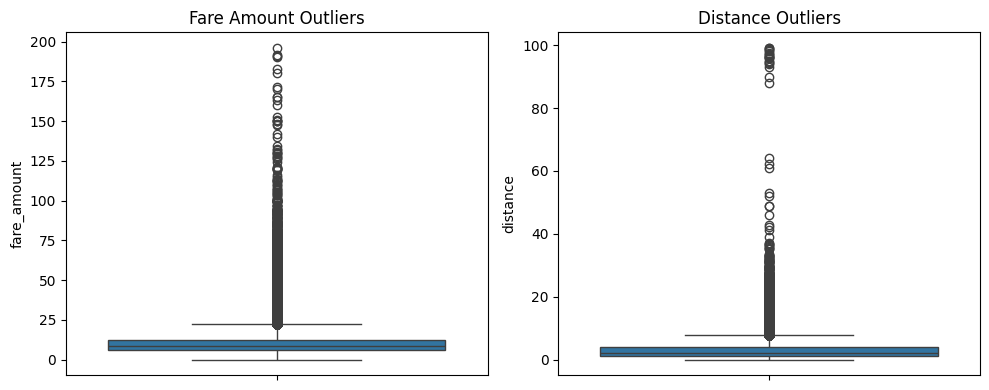


Column: fare_amount
Lower Limit: -3.75
Upper Limit: 22.25
Number of Outliers: 16512

Column: distance
Lower Limit: -2.7079366096153317
Upper Limit: 7.928136813957789
Number of Outliers: 16028


In [7]:

# Boxplot before outlier analysis
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['fare_amount'])
plt.title("Fare Amount Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['distance'])
plt.title("Distance Outliers")

plt.tight_layout()
plt.show()


# Identify outliers using IQR
for col in ['fare_amount', 'distance']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))


In [8]:

for col in ['fare_amount', 'distance']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after outlier removal:", df.shape)


Shape after outlier removal: (168801, 12)


                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000         -0.015299        -0.078051   
pickup_longitude     -0.015299          1.000000         0.396997   
pickup_latitude      -0.078051          0.396997         1.000000   
dropoff_longitude     0.034008          0.676754         0.206899   
dropoff_latitude     -0.109348          0.232486         0.662021   
passenger_count       0.016832         -0.013619        -0.008067   
distance              0.795088         -0.015648        -0.063829   
hour                  0.006843         -0.004626         0.033605   
day                   0.004878         -0.001013        -0.000081   
month                 0.032705         -0.000982        -0.000034   
year                  0.173408         -0.006085        -0.003624   
day_of_week           0.013102         -0.017480        -0.050057   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                

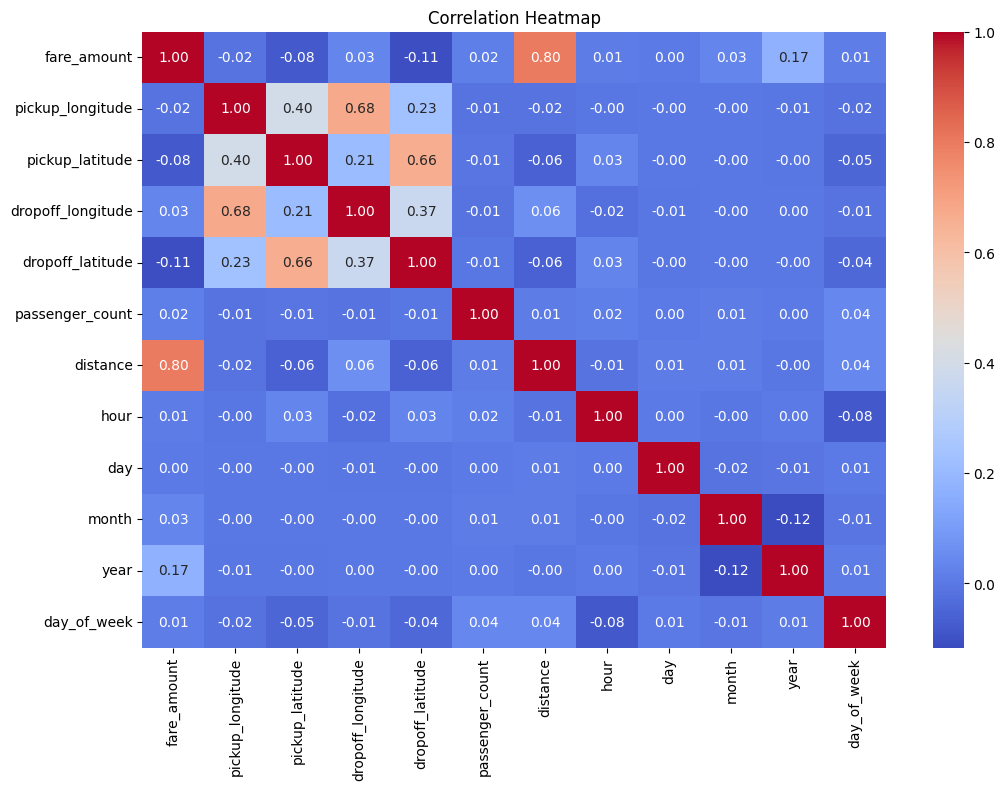

In [9]:

# Calculate correlation matrix
correlation = df.corr(numeric_only=True)

print(correlation)

# Visualize correlation using heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


In [10]:

# Independent variables
X = df.drop('fare_amount', axis=1)

# Dependent variable
y = df['fare_amount']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (135040, 11)
Testing data: (33761, 11)


In [11]:

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained!")


Linear Regression Model Trained!


In [12]:

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained!")


Random Forest Model Trained!


In [15]:

# Linear Regression evaluation
lr_r2 = r2_score(y_test, lr_predictions)
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

# Random Forest evaluation
rf_r2 = r2_score(y_test, rf_predictions)
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

# Display results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'R2 Score': [lr_r2, rf_r2],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse]
})

print(results)


                      Model  R2 Score       MAE      RMSE
0         Linear Regression  0.669463  1.515606  2.128149
1  Random Forest Regression  0.744014  1.297520  1.872838


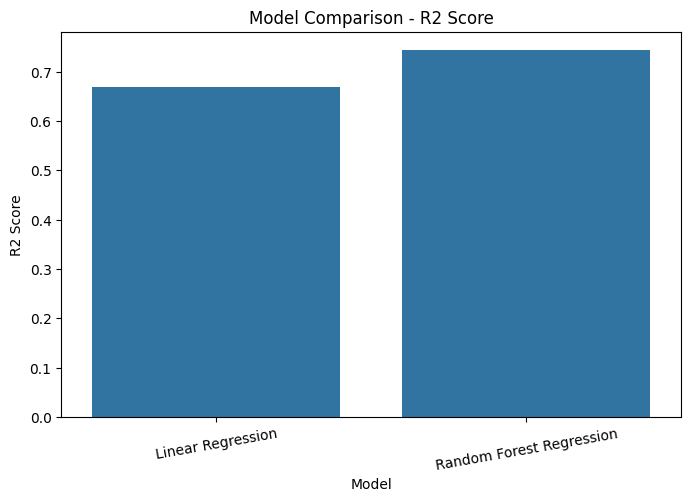

In [16]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='R2 Score'
)

plt.title("Model Comparison - R2 Score")
plt.ylabel("R2 Score")
plt.xticks(rotation=10)
plt.show()


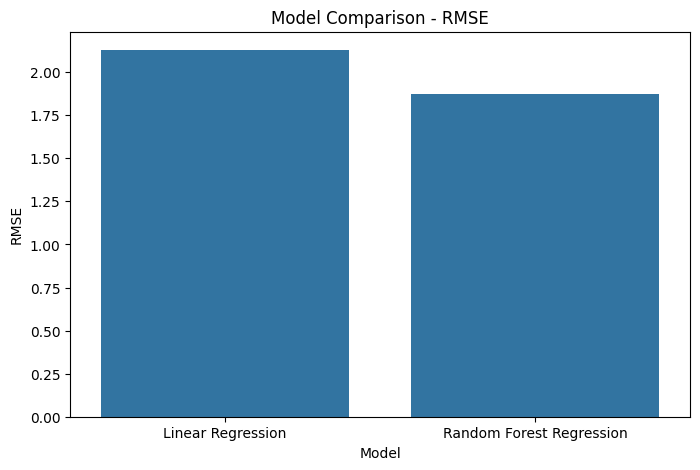

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='RMSE'
)

plt.title("Model Comparison - RMSE")
plt.show()

In [19]:

# Take input from user

pickup_longitude = float(input("Enter pickup longitude: "))
pickup_latitude = float(input("Enter pickup latitude: "))

dropoff_longitude = float(input("Enter dropoff longitude: "))
dropoff_latitude = float(input("Enter dropoff latitude: "))

passenger_count = int(input("Enter passenger count: "))

hour = int(input("Enter pickup hour (0-23): "))
day = int(input("Enter pickup day: "))
month = int(input("Enter pickup month: "))
year = int(input("Enter pickup year: "))
day_of_week = int(input("Enter day of week (0-6): "))

# Calculate distance
distance = calculate_distance(
    pickup_latitude,
    pickup_longitude,
    dropoff_latitude,
    dropoff_longitude
)

# Prepare input in the same feature order as training
new_ride = pd.DataFrame([{
    'pickup_longitude': pickup_longitude,
    'pickup_latitude': pickup_latitude,
    'dropoff_longitude': dropoff_longitude,
    'dropoff_latitude': dropoff_latitude,
    'passenger_count': passenger_count,
    'distance': float(distance),
    'hour': hour,
    'day': day,
    'month': month,
    'year': year,
    'day_of_week': day_of_week
}])

# Predict fare
predicted_fare = rf_model.predict(new_ride)

print("Predicted Uber Fare: $", round(predicted_fare[0], 2))


Enter pickup longitude:  48.8584
Enter pickup latitude:  2.2945
Enter dropoff longitude:  5.6667
Enter dropoff latitude:  67.8888
Enter passenger count:  5
Enter pickup hour (0-23):  3
Enter pickup day:  1
Enter pickup month:  6
Enter pickup year:  2026
Enter day of week (0-6):  5


Predicted Uber Fare: $ 14.86
